# Ejercicio Regression Tree
Son datos de temperaturas tomados de la ciudad de Seattle. El objetivo es intentar predecir lo mejor posible la máxima temperatura (columna `actual`) que alcanzaremos al día siguiente. Para ello contaremos con temperaturas de los dos días anteriores, históricos de máximas temperaturas y un amigo bastante chapas que te da su predicción del tiempo cada día.

**Resumen de datos**:
* year: 2016 for all data points
* month: number for month of the year
* day: number for day of the year
* week: day of the week as a character string
* temp_2: max temperature 2 days prior
* temp_1: max temperature 1 day prior
* average: historical average max temperature
* actual: max temperature measurement
* friend: your friend’s prediction, a random number between 20 below the average and 20 above the average


### 1. Importa el csv "temps.csv"

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
import os
import sklearn
import matplotlib as mpl
import matplotlib.pyplot as plt

In [14]:
df = pd.read_csv("data/temps.csv")
df

,year,month,day,week,temp_2,temp_1,average,actual,friend
0,2016,1,1,Fri,45,45,45.6,45,29
1,2016,1,2,Sat,44,45,45.7,44,61
2,2016,1,3,Sun,45,44,45.8,41,56
3,2016,1,4,Mon,44,41,45.9,40,53
4,2016,1,5,Tues,41,40,46.0,44,41
...,...,...,...,...,...,...,...,...,...
343,2016,12,27,Tues,42,42,45.2,47,47
344,2016,12,28,Wed,42,47,45.3,48,58
345,2016,12,29,Thurs,47,48,45.3,48,65
346,2016,12,30,Fri,48,48,45.4,57,42


### 2. Realiza un análisis exploratorio junto con un Feature Engineering

In [23]:
print("Dimensiones (filas, columnas):", df.shape)
print("\nPrimeras 5 filas:")
print(df.head())

print("\nInformación y nulos:")
print(df.info())

print("\nEstadísticos descriptivos:")
print(df.describe())

Dimensiones (filas, columnas): (348, 9)

Primeras 5 filas:
   year  month  day  week  temp_2  temp_1  average  actual  friend
0  2016      1    1   Fri      45      45     45.6      45      29
1  2016      1    2   Sat      44      45     45.7      44      61
2  2016      1    3   Sun      45      44     45.8      41      56
3  2016      1    4   Mon      44      41     45.9      40      53
4  2016      1    5  Tues      41      40     46.0      44      41

Información y nulos:
<class 'pandas.DataFrame'>
RangeIndex: 348 entries, 0 to 347
Data columns (total 9 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   year     348 non-null    int64  
 1   month    348 non-null    int64  
 2   day      348 non-null    int64  
 3   week     348 non-null    str    
 4   temp_2   348 non-null    int64  
 5   temp_1   348 non-null    int64  
 6   average  348 non-null    float64
 7   actual   348 non-null    int64  
 8   friend   348 non-null    int64  
dtypes

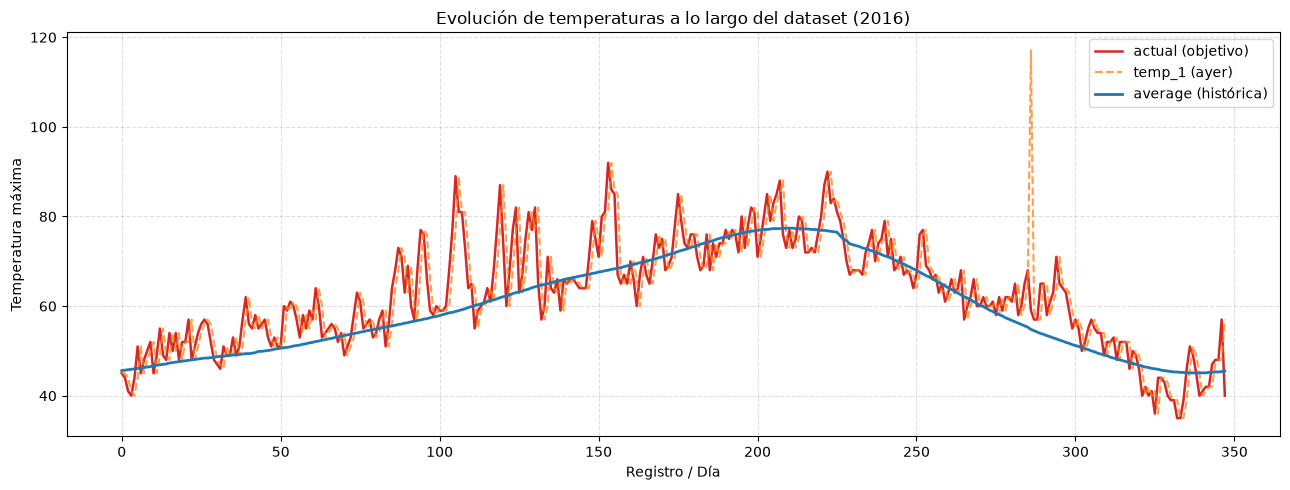

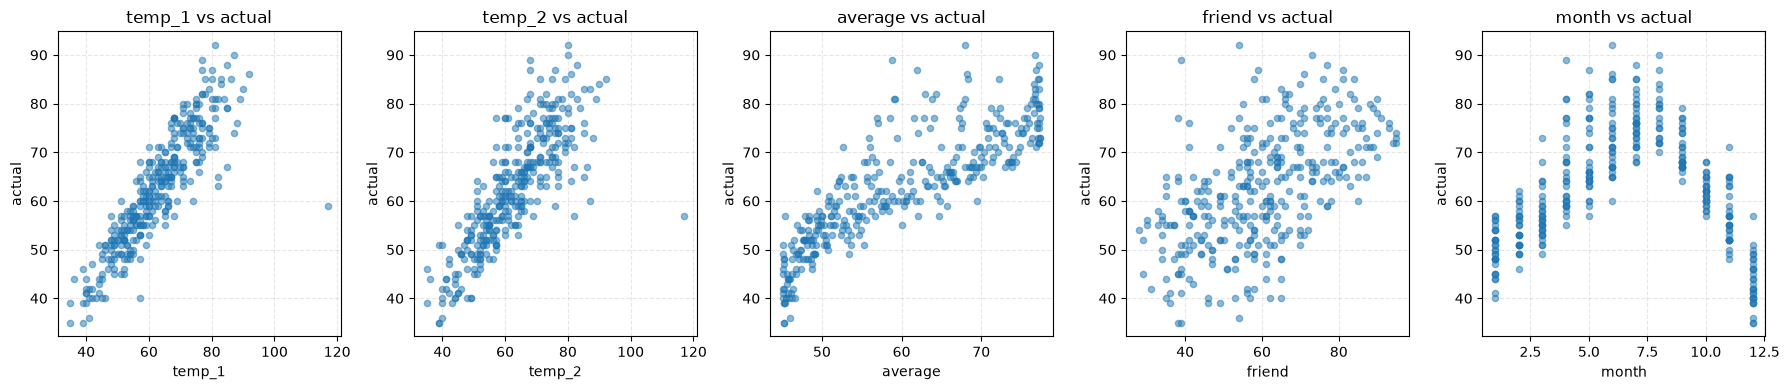

In [24]:
fechas = pd.to_datetime(
    df[["year", "month", "day"]].assign(
        day=df["day"].clip(
            lower=1, upper=28
        )  # ajusta si tu columna 'day' es día del mes
    )
)

# Gráfico 1: Evolución de la temperatura real ('actual') vs promedio histórico ('average') y 'temp_1'
plt.figure(figsize=(13, 5))
plt.plot(
    df.index,
    df["actual"],
    label="actual (objetivo)",
    color="tab:red",
    linewidth=1.8,
)
plt.plot(
    df.index,
    df["temp_1"],
    label="temp_1 (ayer)",
    color="tab:orange",
    alpha=0.75,
    linestyle="--",
)
plt.plot(
    df.index,
    df["average"],
    label="average (histórica)",
    color="tab:blue",
    linewidth=2,
)
plt.title("Evolución de temperaturas a lo largo del dataset (2016)")
plt.xlabel("Registro / Día")
plt.ylabel("Temperatura máxima")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

# Gráfico 2: Dispersión de las variables clave frente a 'actual'
variables_a_ver = ["temp_1", "temp_2", "average", "friend", "month"]
fig, axes = plt.subplots(1, len(variables_a_ver), figsize=(18, 4))

for ax, col in zip(axes, variables_a_ver):
  ax.scatter(df[col], df["actual"], alpha=0.5, s=20)
  ax.set_title(f"{col} vs actual")
  ax.set_xlabel(col)
  ax.set_ylabel("actual")
  ax.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

In [25]:
df_temperatura = df.drop(columns=["friend", "week"]).copy()

In [26]:
df_temperatura.info()

<class 'pandas.DataFrame'>
RangeIndex: 348 entries, 0 to 347
Data columns (total 7 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   year     348 non-null    int64  
 1   month    348 non-null    int64  
 2   day      348 non-null    int64  
 3   temp_2   348 non-null    int64  
 4   temp_1   348 non-null    int64  
 5   average  348 non-null    float64
 6   actual   348 non-null    int64  
dtypes: float64(1), int64(6)
memory usage: 19.2 KB


### 3. Selecciona variables y divide en train y test

In [34]:
from sklearn.tree import DecisionTreeRegressor

In [35]:
from sklearn.model_selection import train_test_split

X = df_temperatura[["year", "month", "day", "temp_2", "temp_1", "average"]]
y = df_temperatura["actual"]

# 2. Dividir en entrenamiento (80%) y prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


### 4. Entrena el modelo


In [50]:
arbol_regresion = DecisionTreeRegressor(random_state=42, max_depth=2)
arbol_regresion.fit(X_train, y_train)


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``

### 5. Evaluación de tu modelo
Calcula el coeficiente de determinación. 

Calcula el MAE, MAPE, MSE y RMSE.

In [51]:
from sklearn import metrics
predictions_train = arbol_regresion.predict(X_train)
# el train muestra como de bueno es el modelo, como de bien se ha entrenado
#el test me dice como de bien funciona en realidad

In [52]:
predictions_test = arbol_regresion.predict(X_test)

In [53]:
print('MAE:', metrics.mean_absolute_error(y_train, predictions_train)) #de media me equivoco 3.6 grafos F en las predicciones de train
print('MAPE:',metrics.mean_absolute_percentage_error(y_train,  predictions_train)) # el porcentaje entre el maximo y mínimo de error en train, un 5,8% de media de error, da el mae en porcentaje
print('MSE:', metrics.mean_squared_error(y_train,  predictions_train))#es rmse al cuadrado, mide lo mismo
print('RMSE:', np.sqrt(metrics.mean_squared_error(y_train,  predictions_train)))# grafos 4.7 F de error, exagera los errores grandes. te da pista de si hay algun error grande. Si el MAE y RMSE son parecidos va bien

MAE: 4.191991861056609
MAPE: 0.06815683252257974
MSE: 28.62210750879816
RMSE: 5.349963318453516


In [54]:
print('MAE:', metrics.mean_absolute_error(y_test, predictions_test))
print('MAPE:',metrics.mean_absolute_percentage_error(y_test, predictions_test))
print('MSE:', metrics.mean_squared_error(y_test, predictions_test))
print('RMSE:', np.sqrt(metrics.mean_squared_error(y_test, predictions_test)))
# si todos funcionan muy bien con train y mal con test esta en overfit el modelo no generaliza, se sabe los datos de memoria
# si las metricas se parecen esta bien, no hay overfit
# errores mas grandes en test

MAE: 4.888811585240156
MAPE: 0.07740495191086964
MSE: 37.64787660374395
RMSE: 6.135786551351338


### 6. Representa el árbol de decisión

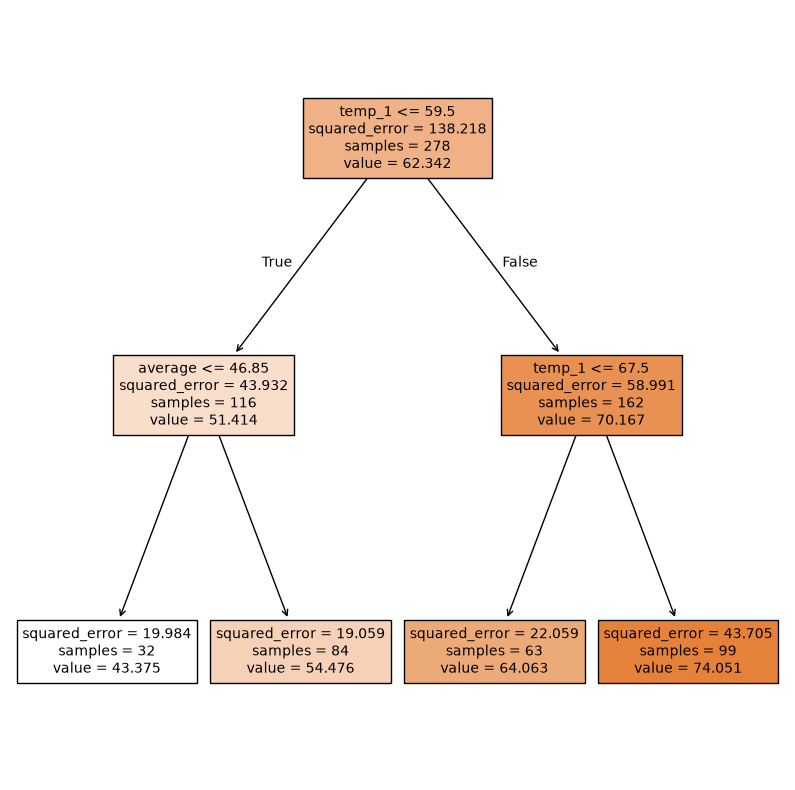

In [55]:
plt.figure(figsize=(10,10)) # vemos el arbol con profundidad 3
sklearn.tree.plot_tree(arbol_regresion,
               feature_names=["year", "month", "day", "temp_2", "temp_1", "average"],
                class_names=None,
               filled = True);

### 7. Modifica el max_depth a 3 y vuelve a entrenarlo

In [56]:
arbol_regresion = DecisionTreeRegressor(random_state=42, max_depth=3)
arbol_regresion.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``

In [58]:
from sklearn import metrics
predictions_train = arbol_regresion.predict(X_train)
predictions_test = arbol_regresion.predict(X_test)

### 8. Vuelve a evaluar tu modelo

In [62]:
print('MAE:', metrics.mean_absolute_error(y_test, predictions_test))
print('MAPE:',metrics.mean_absolute_percentage_error(y_test, predictions_test))
print('MSE:', metrics.mean_squared_error(y_test, predictions_test))
print('RMSE:', np.sqrt(metrics.mean_squared_error(y_test, predictions_test)))
# si todos funcionan muy bien con train y mal con test esta en overfit el modelo no generaliza, se sabe los datos de memoria
# si las metricas se parecen esta bien, no hay overfit
# errores mas grandes en test

MAE: 4.267242249556827
MAPE: 0.0674392768128964
MSE: 30.946461197509944
RMSE: 5.5629543587476915


In [59]:
print('MAE:', metrics.mean_absolute_error(y_train, predictions_train)) #de media me equivoco 3.6 grafos F en las predicciones de train
print('MAPE:',metrics.mean_absolute_percentage_error(y_train,  predictions_train)) # el porcentaje entre el maximo y mínimo de error en train, un 5,8% de media de error, da el mae en porcentaje
print('MSE:', metrics.mean_squared_error(y_train,  predictions_train))#es rmse al cuadrado, mide lo mismo
print('RMSE:', np.sqrt(metrics.mean_squared_error(y_train,  predictions_train)))# grafos 4.7 F de error, exagera los errores grandes. te da pista de si hay algun error grande. Si el MAE y RMSE son parecidos va bien

MAE: 3.675752083754991
MAPE: 0.05874668452706153
MSE: 22.14996536445183
RMSE: 4.706374970659672


### 9. Vuelve a representar su árbol

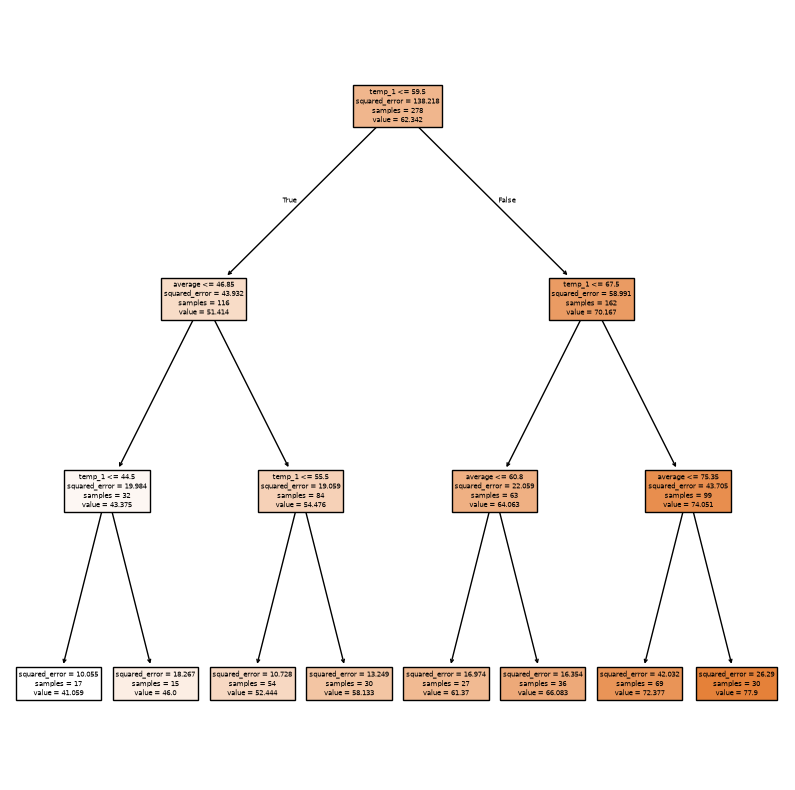

In [61]:
plt.figure(figsize=(10,10)) # vemos el arbol con profundidad 3
sklearn.tree.plot_tree(arbol_regresion,
               feature_names=["year", "month", "day", "temp_2", "temp_1", "average"],
                class_names=None,
               filled = True);

### 10. Utiliza un grid search con cross validation para hiperparametrizar tu modelo

In [63]:
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.tree import DecisionTreeRegressor

# 1. Modelo base
arbol = DecisionTreeRegressor(random_state=42)

# 2. Rejilla de hiperparámetros a probar
param_grid = {
    "max_depth": [2, 3, 4, 5, 6, 8, None],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 3, 5, 10],
    # va a probar arboles de más de 2, 3,4 de profundidad...
    # va a probar tambien con el minimo de particiones, no psrtir un nodo si tiene menos datos que X
    # va a probar minimo de elementos en l final del arbol, que no divida si el minimo de elementos en la hoja es X
    # para sber cuantos arboles va a probar es multiplicar las pruebas que están en param_grid
    #el primer arbol seria max depth de 2, min samples split 2 y min samples leaf de 1
    # el siguiente seria max depth de 2, min samples split 2 y min samples leaf de 3...
}

# 3. Validación cruzada (5 folds) optimizando MAE
cv = KFold(n_splits=5, shuffle=True, random_state=42) # esto hace que cada arbol lo prueb 5 veces con diferentes datos de X_train y de esos datos deja unos para x_test. cada vez que lo hace los mezcla con shuffle

grid_search = GridSearchCV(# esto hace las pruebas con las dos metricas, param_grid y con cv. 
    estimator=arbol, # este es el arbol
    param_grid=param_grid,
    scoring="neg_mean_absolute_error", # metrica del MAE, el scoring va a sacar siempre el más alto, entonces se pone negativo para que si es el mas alto 3 en negativo pillaria como el más alto un -2 o algo asi
    cv=cv, 
    n_jobs=-1,#para usar todos los cores que tiene para hacerlo
    return_train_score=True, #me devuelve la metrica del scoring
) # cada arbol probado se califica como estimator

# 4. Ajustar sobre los datos de entrenamiento ya limpios
grid_search.fit(X_train, y_train)

# 5. Resultados en validación cruzada y evaluación final en test
mejor_mae_cv = -grid_search.best_score_ #ahora como el scoring se quedo negativo ahora lo convierto en positivo por el -
print("Mejores hiperparámetros:", grid_search.best_params_)
print(f"Mejor MAE en validación cruzada (CV): {mejor_mae_cv:.4f}")

mejor_arbol = grid_search.best_estimator_
preds_test = mejor_arbol.predict(X_test)

print(f"MAE en test: {mean_absolute_error(y_test, preds_test):.4f}")
print(f"R2 en test:  {r2_score(y_test, preds_test):.4f}")

Mejores hiperparámetros: {'max_depth': 5, 'min_samples_leaf': 10, 'min_samples_split': 2}
Mejor MAE en validación cruzada (CV): 4.0395
MAE en test: 3.8300
R2 en test:  0.8233


### 11. Obten el `feature_importances` de cada variable en el último modelo

In [64]:
importancias = pd.Series(
    grid_search.best_estimator_.feature_importances_, index=X_train.columns
).sort_values(ascending=False)

print(importancias)

temp_1     0.867727
average    0.131446
day        0.000827
year       0.000000
month      0.000000
temp_2     0.000000
dtype: float64


### 12. Construye un nuevo modelo `DecisionTreeClassifier` que te clasifique cuando en un día va a hacer una temperatura mayor a 15ºC (59ºF). ¡Deberá tratarse como un problema de **clasificación**! Utiliza un grid search con cross validation y evalúa el mejor modelo.

In [67]:
df_clf = df_temperatura.copy()
df_clf["objetivo"] = (df_clf["actual"] > 59).astype(int)

print(df_clf["objetivo"].value_counts())

objetivo
1    204
0    144
Name: count, dtype: int64


In [68]:
from sklearn.model_selection import train_test_split

X = df_clf.drop(columns=["actual", "objetivo"])
y = df_clf["objetivo"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (278, 6) | Test: (70, 6)


In [69]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier

param_grid = {
    "max_depth": [2, 3, 4, 5, 6, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 3, 5],
}

grid_clf = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
)

grid_clf.fit(X_train, y_train)

print("Mejores parámetros:", grid_clf.best_params_)
print(f"Mejor accuracy en CV: {grid_clf.best_score_:.4f}")

Mejores parámetros: {'max_depth': 3, 'min_samples_leaf': 5, 'min_samples_split': 2}
Mejor accuracy en CV: 0.9210


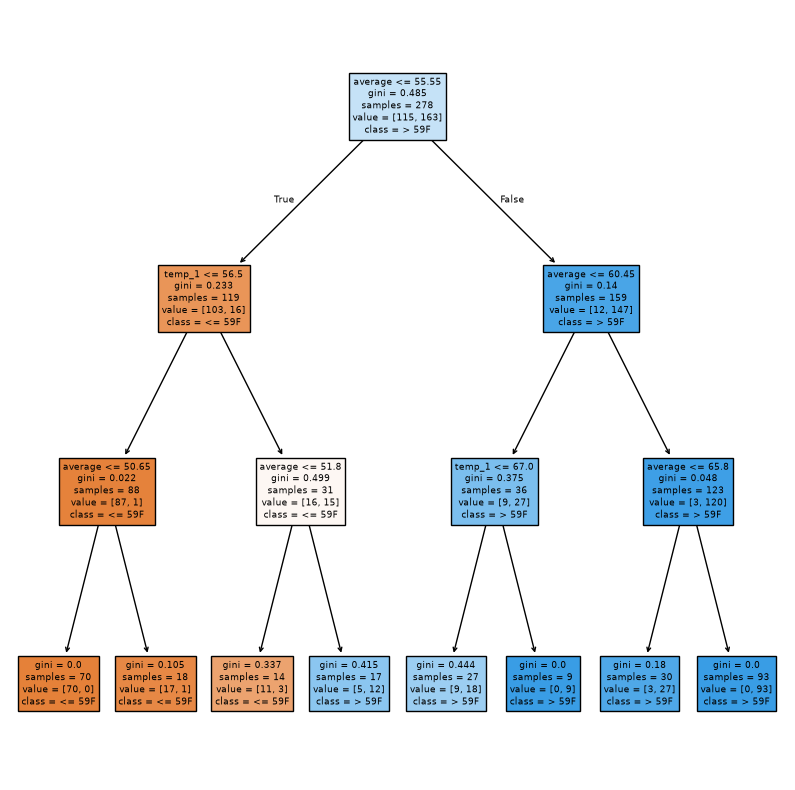

In [71]:
plt.figure(figsize=(10, 10))  # vemos el arbol con profundidad 3
sklearn.tree.plot_tree(
    grid_clf.best_estimator_,
    feature_names=["year", "month", "day", "temp_2", "temp_1", "average"],
    class_names=["<= 59F", "> 59F"],
    filled=True,
)
plt.show()

In [70]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
)

mejor_modelo = grid_clf.best_estimator_
y_pred = mejor_modelo.predict(X_test)

print(f"Accuracy en test: {accuracy_score(y_test, y_pred):.4f}\n")
print("Matriz de confusión:")
print(confusion_matrix(y_test, y_pred))
print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred))

Accuracy en test: 0.9143

Matriz de confusión:
[[23  6]
 [ 0 41]]

Reporte de clasificación:
              precision    recall  f1-score   support

           0       1.00      0.79      0.88        29
           1       0.87      1.00      0.93        41

    accuracy                           0.91        70
   macro avg       0.94      0.90      0.91        70
weighted avg       0.93      0.91      0.91        70

